# Customer Value Map — NexaRetail RFM Segmentation
**Project 4 · PrimrIQ Data Analytics Internship**

**Prepared by:** Archit Verma
**For:** Sneha Kulkarni, Head of Marketing, NexaRetail

---

### Business Question
NexaRetail's loyalty programme has 2,500 enrolled customers. Marketing needs a simple answer to three questions:

1. **Who is valuable** — which customers should we protect and reward?
2. **Who is at risk** — which customers are slipping away, and what would it cost to lose them?
3. **Who is already gone** — where should we stop spending marketing effort?

This notebook builds an **RFM (Recency, Frequency, Monetary) segmentation** on the transaction history to answer this in plain business terms — segment sizes, revenue at stake, and a recommended action for each group.

## 1. Setup

Loading the standard data-analysis stack: `pandas`/`numpy` for data handling, `matplotlib`/`seaborn` for charts.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from datetime import datetime

sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 110
pd.options.display.float_format = '{:,.2f}'.format

## 2. Load & Inspect the Data

The dataset is transaction-level: one row per purchase, ~19,100 transactions across 2,500 loyalty customers.

In [2]:
df = pd.read_csv("P4_Dataset.csv")
print(f"Rows: {df.shape[0]:,}  |  Columns: {df.shape[1]}")
df.head()

Rows: 19,113  |  Columns: 7


,customer_id,customer_name,city,state,transaction_date,amount,category
0,NEXA-00001,Shinde Traders #33,Pune,Maharashtra,2023-02-27,"2,873.14",Snacks
1,NEXA-00001,Shinde Traders #33,Pune,Maharashtra,2023-08-24,"1,184.13",Beverages
2,NEXA-00001,Shinde Traders #33,Pune,Maharashtra,2023-09-11,"7,872.38",Snacks
3,NEXA-00001,Shinde Traders #33,Pune,Maharashtra,2022-09-03,"12,183.84",Dal
4,NEXA-00001,Shinde Traders #33,Pune,Maharashtra,2022-06-10,"7,770.58",Dal


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19113 entries, 0 to 19112
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       19113 non-null  str    
 1   customer_name     19113 non-null  str    
 2   city              19113 non-null  str    
 3   state             19113 non-null  str    
 4   transaction_date  19113 non-null  str    
 5   amount            19113 non-null  float64
 6   category          19113 non-null  str    
dtypes: float64(1), str(6)
memory usage: 1.0 MB


### Data quality checks

Before computing RFM, we check for the three things that would break the analysis: missing values, duplicate rows, and invalid (negative/zero) transaction amounts.

In [4]:
checks = pd.DataFrame({
    "Missing values": df.isnull().sum(),
    "Duplicate rows": [df.duplicated().sum()] * len(df.columns),
})
checks

,Missing values,Duplicate rows
customer_id,0,0
customer_name,0,0
city,0,0
state,0,0
transaction_date,0,0
amount,0,0
category,0,0


In [5]:
print(f"Negative-amount transactions: {(df['amount'] < 0).sum()}")
print(f"Zero-amount transactions: {(df['amount'] == 0).sum()}")
print(f"Unique customers: {df['customer_id'].nunique()}")
print(f"Date range: {df['transaction_date'].min()} to {df['transaction_date'].max()}")

Negative-amount transactions: 0
Zero-amount transactions: 0
Unique customers: 2500
Date range: 2022-01-07 to 2024-06-16


In [6]:
df['transaction_date'] = pd.to_datetime(df['transaction_date'], format="%Y-%m-%d")
df.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
customer_id,19113,2500,NEXA-00015,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_name,19113,1846,Reliance Fresh Baner #33,86,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,19113,10,Kolhapur,2096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,19113,2,Maharashtra,11549,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction_date,19113,NaN,NaN,NaN,2023-03-21 18:29:01.516245,2022-01-07 00:00:00,2022-11-04 00:00:00,2023-03-21 00:00:00,2023-08-06 00:00:00,2024-06-16 00:00:00,NaN
amount,"19,113.00",NaN,NaN,NaN,"7,596.25",200.73,"3,875.04","7,576.35","11,303.86","14,999.63","4,284.69"
category,19113,8,Snacks,2481,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Result:** no missing values, no duplicate rows, no negative or zero amounts. The data is clean and ready for RFM aggregation.

## 3. Building the RFM Table

For each customer we compute:

- **Recency (R)** — days since their last purchase, measured from the dataset's reference date of **30 June 2024** (per the dataset guide). Lower is better.
- **Frequency (F)** — total number of transactions. Higher is better.
- **Monetary (M)** — total amount spent (₹). Higher is better.

In [7]:
snapshot_date = datetime(2024, 6, 30)

rfm = df.groupby('customer_id').agg(
    last_purchase=('transaction_date', 'max'),
    frequency=('customer_id', 'count'),
    monetary=('amount', 'sum')
)
rfm['recency'] = (snapshot_date - rfm['last_purchase']).dt.days

rfm[['recency', 'frequency', 'monetary']].head()

,recency,frequency,monetary
customer_id,,,
NEXA-00001,293,30,"201,034.97"
NEXA-00002,260,2,"20,547.41"
NEXA-00003,90,8,"46,745.69"
NEXA-00004,49,30,"245,393.19"
NEXA-00005,159,3,"39,571.42"


### Distribution of R, F, M

A quick look at the shape of each metric before scoring — this confirms the dataset guide's note that frequency is heavily skewed (most customers have very few transactions, a handful have 30+).

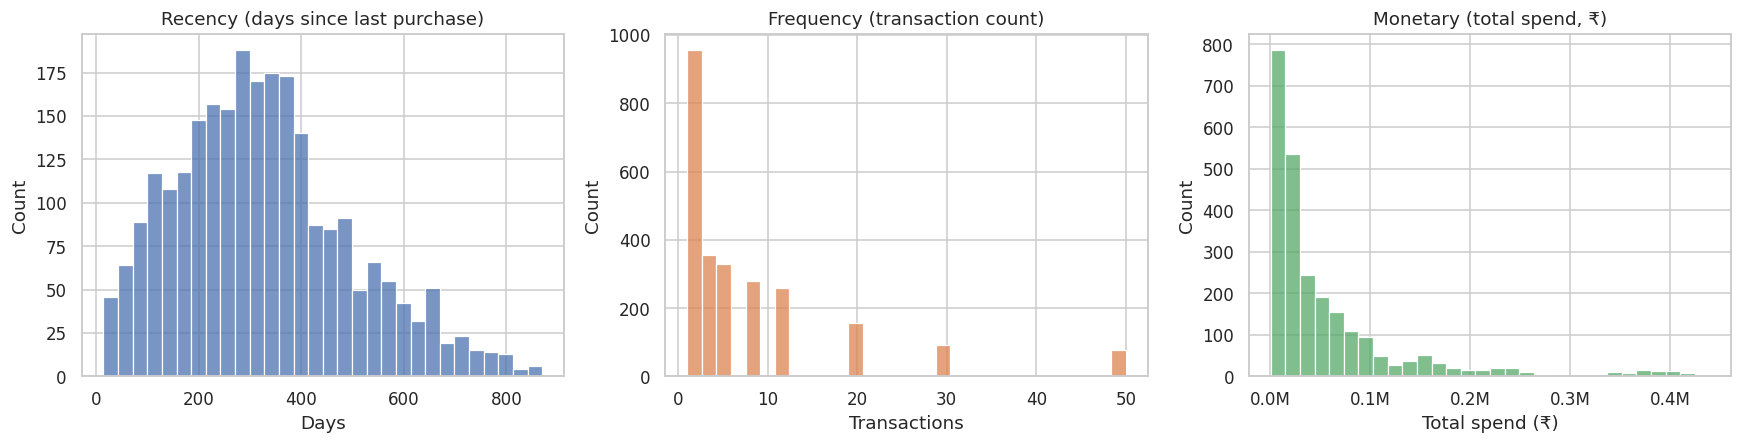

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

sns.histplot(rfm['recency'], bins=30, color='#4C72B0', ax=axes[0])
axes[0].set_title('Recency (days since last purchase)')
axes[0].set_xlabel('Days')

sns.histplot(rfm['frequency'], bins=30, color='#DD8452', ax=axes[1])
axes[1].set_title('Frequency (transaction count)')
axes[1].set_xlabel('Transactions')

sns.histplot(rfm['monetary'], bins=30, color='#55A868', ax=axes[2])
axes[2].set_title('Monetary (total spend, ₹)')
axes[2].set_xlabel('Total spend (₹)')
axes[2].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e6:.1f}M'))

plt.tight_layout()
plt.show()

**Reading the charts:** frequency is right-skewed exactly as expected — most customers have only 1–3 transactions, with a long tail of highly frequent buyers. This is why we score customers with **quartiles (`pd.qcut`)** rather than fixed cut-offs: it automatically adapts to this skew and splits customers into four equal-sized groups per metric.

## 4. Quartile Scoring (1–4 scale)

Each customer gets a score of 1–4 on each metric, based on which quartile they fall into:

- **M_score / F_score:** 4 = highest spend / most frequent, 1 = lowest.
- **R_score:** reversed — 4 = most recent purchase, 1 = longest since last purchase — so that a score of 4 always means "good for the business" across all three metrics.

In [9]:
rfm['M_score'] = pd.qcut(rfm['monetary'], 4, labels=['1', '2', '3', '4'])
rfm['F_score'] = pd.qcut(rfm['frequency'], 4, labels=['1', '2', '3', '4'])
rfm['R_score'] = pd.qcut(rfm['recency'], 4, labels=['4', '3', '2', '1'])

rfm[['recency', 'R_score', 'frequency', 'F_score', 'monetary', 'M_score']].head(8)

,recency,R_score,frequency,F_score,monetary,M_score
customer_id,,,,,,
NEXA-00001,293,3,30,4,"201,034.97",4
NEXA-00002,260,3,2,1,"20,547.41",2
NEXA-00003,90,4,8,3,"46,745.69",3
NEXA-00004,49,4,30,4,"245,393.19",4
NEXA-00005,159,4,3,2,"39,571.42",3
NEXA-00006,579,1,3,2,"26,295.26",2
NEXA-00007,46,4,20,4,"162,080.50",4
NEXA-00008,36,4,8,3,"84,643.10",4


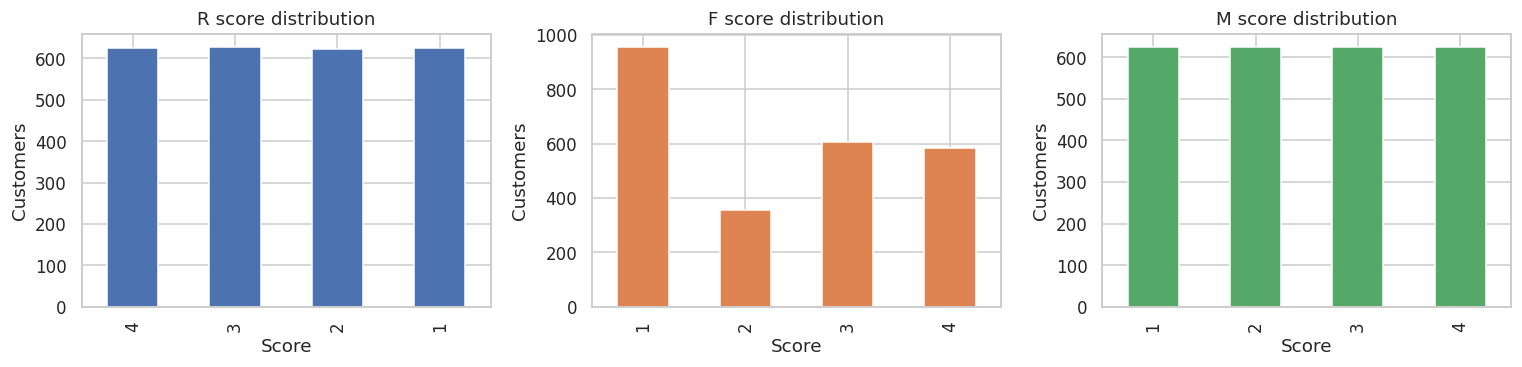

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col, title, color in zip(
    axes, ['R_score', 'F_score', 'M_score'],
    ['R score distribution', 'F score distribution', 'M score distribution'],
    ['#4C72B0', '#DD8452', '#55A868']
):
    rfm[col].value_counts().sort_index().plot(kind='bar', ax=ax, color=color)
    ax.set_title(title)
    ax.set_xlabel('Score')
    ax.set_ylabel('Customers')
plt.tight_layout()
plt.show()

Each quartile holds roughly 625 customers (2,500 ÷ 4), confirming the quartile split worked as intended.

## 5. Customer Segmentation

Raw R/F/M scores aren't something Sneha can act on directly — they need to be translated into named, business-readable segments. The rules below combine the three scores into six segments:

| Segment | Rule | Business Meaning |
|---|---|---|
| **Champions** | R≥3, F≥3, M≥3 | Most valuable customers — buy often, recently, and spend significantly. |
| **Loyal** | R≥3, F≥2, M≥2 | Consistently engaged, but spend/frequency slightly lower than Champions. |
| **At Risk** | R≤2, F≥3, M≥3 | Previously high-value customers who have gone quiet — the priority win-back group. |
| **Hibernating** | R≤1, F≥2, M≥2 | Long inactive, moderate historical value — worth a low-cost nudge. |
| **Lost** | R=1, F=1, M=1 | Low value and inactive on every dimension — not worth active spend. |
| **Need Attention** | *(everything else)* | Doesn't cleanly fit the above — moderate potential, needs nurturing. |

Segments are checked in the order above (`np.select` applies the first matching rule), so a customer is only ever placed in one segment.

In [11]:
conditions = [
    (rfm['R_score'] >= '3') & (rfm['F_score'] >= '3') & (rfm['M_score'] >= '3'),   # Champions
    (rfm['R_score'] >= '3') & (rfm['F_score'] >= '2') & (rfm['M_score'] >= '2'),   # Loyal
    (rfm['R_score'] <= '2') & (rfm['F_score'] >= '3') & (rfm['M_score'] >= '3'),   # At Risk
    (rfm['R_score'] <= '1') & (rfm['F_score'] >= '2') & (rfm['M_score'] >= '2'),   # Hibernating
    (rfm['R_score'] == '1') & (rfm['F_score'] == '1') & (rfm['M_score'] == '1'),   # Lost
]
choices = ['Champions', 'Loyal', 'At Risk', 'Hibernating', 'Lost']

rfm['segment'] = np.select(conditions, choices, default='Need Attention')
rfm['avg_transaction_value'] = rfm['monetary'] / rfm['frequency']

rfm['segment'].value_counts()

segment
Champions         721
Need Attention    677
At Risk           421
Lost              315
Loyal             295
Hibernating        71
Name: count, dtype: int64

## 6. Segment-Level Business Summary

This is the table Sneha actually needs: for each segment, how many customers, how much revenue, average transaction size, and what share of total loyalty revenue it represents.

In [12]:
segment_summary = rfm.groupby('segment').agg(
    customers=('frequency', 'count'),
    revenue=('monetary', 'sum'),
    total_transactions=('frequency', 'sum')
)
segment_summary['avg_transaction_value'] = segment_summary['revenue'] / segment_summary['total_transactions']
segment_summary['revenue_pct'] = segment_summary['revenue'] / segment_summary['revenue'].sum() * 100

recommendations = {
    'Champions': 'Reward with VIP benefits, early access and referral incentives.',
    'Loyal': 'Encourage higher spending through upselling and bundle offers.',
    'At Risk': 'Launch personalized win-back campaigns with limited-time discounts.',
    'Hibernating': 'Re-engage using reminder emails and targeted promotions.',
    'Need Attention': 'Nurture with personalized product recommendations and loyalty rewards.',
    'Lost': 'Minimize marketing spend; include only in broad awareness campaigns.',
}
segment_summary['recommended_action'] = segment_summary.index.map(recommendations)
segment_summary = segment_summary.sort_values('revenue', ascending=False)

segment_summary.style.format({
    'revenue': '₹{:,.0f}',
    'total_transactions': '{:,.0f}',
    'avg_transaction_value': '₹{:,.0f}',
    'revenue_pct': '{:.1f}%'
}).bar(subset=['revenue_pct'], color='#5DA5DA')

,customers,revenue,total_transactions,avg_transaction_value,revenue_pct,recommended_action
segment,,,,,,
Champions,721,"₹75,028,351","9,808","₹7,650",51.7%,"Reward with VIP benefits, early access and referral incentives."
At Risk,421,"₹50,602,733","6,632","₹7,630",34.9%,Launch personalized win-back campaigns with limited-time discounts.
Need Attention,677,"₹8,725,170","1,114","₹7,832",6.0%,Nurture with personalized product recommendations and loyalty rewards.
Loyal,295,"₹6,902,437",955,"₹7,228",4.8%,Encourage higher spending through upselling and bundle offers.
Lost,315,"₹2,192,380",369,"₹5,941",1.5%,Minimize marketing spend; include only in broad awareness campaigns.
Hibernating,71,"₹1,735,976",235,"₹7,387",1.2%,Re-engage using reminder emails and targeted promotions.


### Revenue and customer count by segment

/tmp/ipykernel_593/2434301341.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='revenue', y=segment_summary.index, data=segment_summary, order=order, palette='viridis', ax=axes[0])
/tmp/ipykernel_593/2434301341.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='customers', y=segment_summary.index, data=segment_summary, order=order, palette='magma', ax=axes[1])


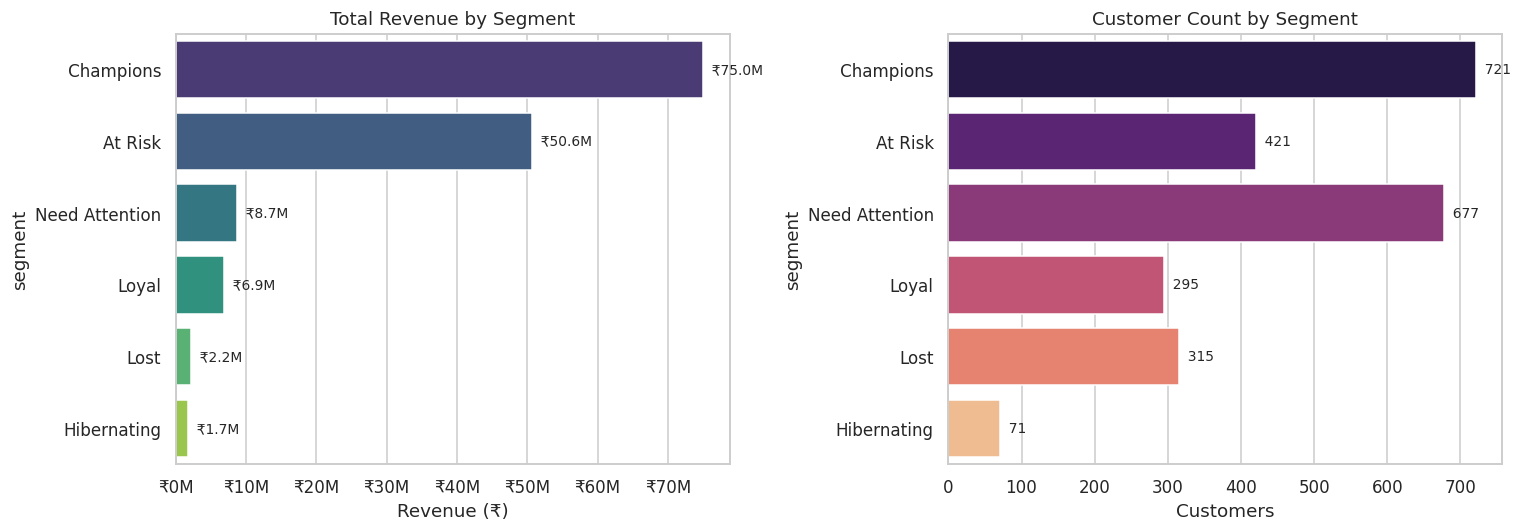

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

order = segment_summary.index

sns.barplot(x='revenue', y=segment_summary.index, data=segment_summary, order=order, palette='viridis', ax=axes[0])
axes[0].set_title('Total Revenue by Segment')
axes[0].set_xlabel('Revenue (₹)')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₹{x/1e6:.0f}M'))
for i, v in enumerate(segment_summary['revenue']):
    axes[0].text(v, i, f"  ₹{v/1e6:.1f}M", va='center', fontsize=9)

sns.barplot(x='customers', y=segment_summary.index, data=segment_summary, order=order, palette='magma', ax=axes[1])
axes[1].set_title('Customer Count by Segment')
axes[1].set_xlabel('Customers')
for i, v in enumerate(segment_summary['customers']):
    axes[1].text(v, i, f"  {v:,}", va='center', fontsize=9)

plt.tight_layout()
plt.show()

### Revenue share by segment

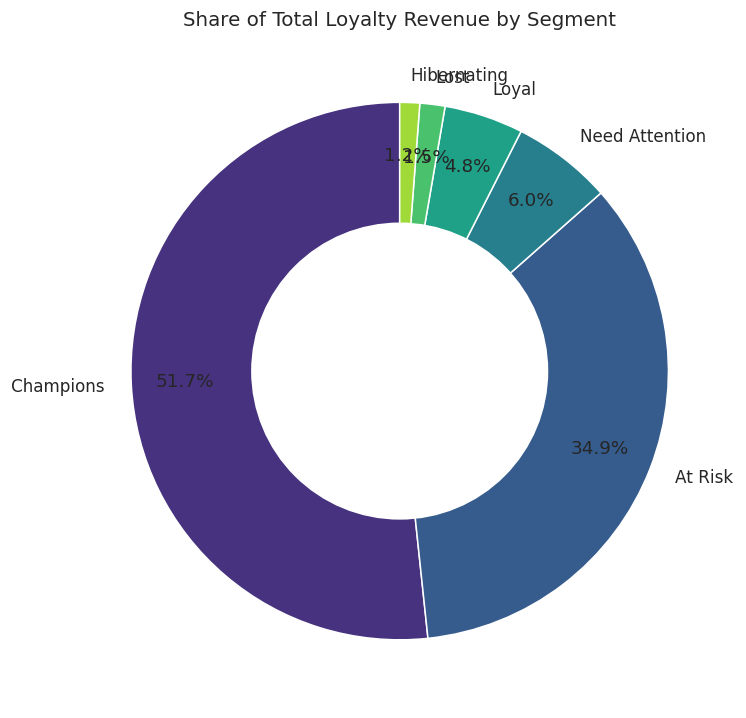

In [14]:
fig, ax = plt.subplots(figsize=(7, 7))
colors = sns.color_palette('viridis', len(segment_summary))
wedges, texts, autotexts = ax.pie(
    segment_summary['revenue'],
    labels=segment_summary.index,
    autopct='%1.1f%%',
    colors=colors,
    startangle=90,
    pctdistance=0.8
)
centre_circle = plt.Circle((0, 0), 0.55, fc='white')
ax.add_artist(centre_circle)
ax.set_title('Share of Total Loyalty Revenue by Segment', fontsize=13)
plt.tight_layout()
plt.show()

## 7. Revenue at Stake — At Risk Segment Deep-Dive

The brief specifically calls out quantifying what's at stake in the **At Risk** segment: customers who used to buy frequently and spend significantly, but have gone quiet recently.

In [15]:
at_risk = rfm[rfm['segment'] == 'At Risk']
champions = rfm[rfm['segment'] == 'Champions']

at_risk_customers = len(at_risk)
at_risk_revenue = at_risk['monetary'].sum()
at_risk_pct = at_risk_revenue / rfm['monetary'].sum() * 100
at_risk_avg_recency = at_risk['recency'].mean()
at_risk_avg_txn = at_risk['avg_transaction_value'].mean()

print(f"At Risk customers          : {at_risk_customers:,}")
print(f"At Risk historical revenue : ₹{at_risk_revenue:,.0f}")
print(f"Share of total revenue      : {at_risk_pct:.2f}%")
print(f"Average days since last buy : {at_risk_avg_recency:.0f} days")
print(f"Average transaction value  : ₹{at_risk_avg_txn:,.0f}")

At Risk customers          : 421
At Risk historical revenue : ₹50,602,733
Share of total revenue      : 34.85%
Average days since last buy : 118 days
Average transaction value  : ₹7,675


In [16]:
comparison = pd.DataFrame({
    'Champions (retained)': [len(champions), champions['monetary'].sum(), champions['recency'].mean()],
    'At Risk (recoverable)': [at_risk_customers, at_risk_revenue, at_risk_avg_recency],
}, index=['Customers', 'Historical Revenue (₹)', 'Avg. Recency (days)']).T

comparison.style.format({'Customers': '{:,.0f}', 'Historical Revenue (₹)': '₹{:,.0f}', 'Avg. Recency (days)': '{:.0f}'})

,Customers,Historical Revenue (₹),Avg. Recency (days)
Champions (retained),721,"₹75,028,351",323
At Risk (recoverable),421,"₹50,602,733",118


**Business read:** the At Risk segment looks almost identical to Champions on frequency and spend — the *only* difference is recency. These are high-value customers who have simply stopped buying recently. That combination (high historical value + recent silence) is exactly what a win-back campaign is designed to fix, which is why this segment deserves priority budget over Hibernating or Lost.

## 8. Key Business Insights

In [17]:
top_seg = segment_summary.index[0]
top_row = segment_summary.iloc[0]
second_seg_rows = segment_summary.drop(index='Champions', errors='ignore')
need_attn = segment_summary.loc['Need Attention'] if 'Need Attention' in segment_summary.index else None

print("INSIGHT 1")
print(f"{top_seg} account for {top_row['revenue_pct']:.2f}% of total revenue from just {int(top_row['customers']):,} customers "
      f"({int(top_row['customers'])/len(rfm)*100:.1f}% of the customer base). Losing this group would be far more damaging "
      "than losing any other segment.")
print()
print("INSIGHT 2")
print(f"The At Risk segment holds {at_risk_pct:.2f}% of total revenue (₹{at_risk_revenue/1e6:.1f}M) across {at_risk_customers:,} customers. "
      "A targeted win-back campaign here has the single largest revenue-recovery potential of any non-Champion segment.")
print()
if need_attn is not None:
    print("INSIGHT 3")
    print(f"Need Attention is the {'largest' if need_attn['customers']==segment_summary['customers'].max() else 'second-largest'} "
          f"customer group ({int(need_attn['customers']):,} customers) but contributes only {need_attn['revenue_pct']:.2f}% of revenue — "
          "personalized offers here could convert volume into value by nudging them toward Loyal.")

INSIGHT 1
Champions account for 51.68% of total revenue from just 721 customers (28.8% of the customer base). Losing this group would be far more damaging than losing any other segment.

INSIGHT 2
The At Risk segment holds 34.85% of total revenue (₹50.6M) across 421 customers. A targeted win-back campaign here has the single largest revenue-recovery potential of any non-Champion segment.

INSIGHT 3
Need Attention is the second-largest customer group (677 customers) but contributes only 6.01% of revenue — personalized offers here could convert volume into value by nudging them toward Loyal.


## 9. Segment Recommendations (Quick Reference)

| Segment | Recommended Action |
|---|---|
| **Champions** | Reward with VIP benefits, early access and referral incentives. |
| **Loyal** | Encourage higher spending through upselling and bundle offers. |
| **At Risk** | Launch personalized win-back campaigns with limited-time discounts. |
| **Hibernating** | Re-engage using reminder emails and targeted promotions. |
| **Need Attention** | Nurture with personalized product recommendations and loyalty rewards. |
| **Lost** | Minimize marketing spend; include only in broad awareness campaigns. |

## 10. Export Deliverables

Saving the two files required by the brief:

- **`NexaRetail_Segments_ArchitVerma.xlsx`** — one sheet with the segment-level summary, one sheet with customer-level R/F/M scores and segment labels.

In [18]:
customer_export = rfm.reset_index()[[
    'customer_id', 'recency', 'frequency', 'monetary',
    'R_score', 'F_score', 'M_score', 'avg_transaction_value', 'segment'
]].rename(columns={
    'recency': 'recency_days',
    'monetary': 'monetary_inr',
    'avg_transaction_value': 'avg_transaction_value_inr'
})

segment_export = segment_summary.reset_index().rename(columns={
    'segment': 'Segment',
    'customers': 'Customers',
    'revenue': 'Revenue (INR)',
    'total_transactions': 'Total Transactions',
    'avg_transaction_value': 'Avg Transaction Value (INR)',
    'revenue_pct': 'Revenue %',
    'recommended_action': 'Recommended Action'
})

with pd.ExcelWriter('NexaRetail_Segments_ArchitVerma.xlsx', engine='openpyxl') as writer:
    segment_export.to_excel(writer, sheet_name='Segment Summary', index=False)
    customer_export.to_excel(writer, sheet_name='Customer Detail', index=False)

print("Saved: NexaRetail_Segments_ArchitVerma.xlsx")

Saved: NexaRetail_Segments_ArchitVerma.xlsx


---

### Summary for Sneha

- **721 Champions** (29% of customers) drive **~52% of loyalty revenue** — protect this group above all else.
- **421 At Risk customers** represent **~₹50.6M (35%) of revenue** that is still recoverable with a focused win-back push — this is the single highest-leverage campaign to run next.
- **Lost and Hibernating customers** (386 combined) contribute under **3% of revenue** — not worth active marketing spend.
- Full customer-level segment labels and R/F/M scores are in the exported Excel file for the campaign team to action directly.